In [1]:
# IMPORT LIBRARIES
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.float_format', lambda x: '%.3f' % x)
plt.rcParams["figure.figsize"] = (10,6)

In [2]:
print("Current working directory:", os.getcwd())
print("Dataset files:", os.listdir("datasets/nsl-kdd"))

Current working directory: /home/lkg/ml
Dataset files: ['KDDTest+.arff', 'KDDTest+.txt', 'KDDTrain+.txt', 'KDDTrain1.jpg', 'KDDTrain+_20Percent.txt', 'KDDTest-21.arff', 'index.html', 'KDDTest1.jpg', 'KDDTrain+.arff', 'KDDTest-21.txt', 'KDDTrain+_20Percent.arff']


In [3]:
#2. READ DATASET
df_0 = pd.read_csv("datasets/nsl-kdd/KDDTrain+.txt")
df= df_0.copy()
df.head()

,0,tcp,ftp_data,SF,491,0.1,0.2,0.3,0.4,0.5,...,0.17,0.03,0.17.1,0.00.6,0.00.7,0.00.8,0.05,0.00.9,normal,20
0,0,udp,other,SF,146,0,0,0,0,0,...,0.000,0.600,0.880,0.000,0.000,0.000,0.000,0.000,normal,15
1,0,tcp,private,S0,0,0,0,0,0,0,...,0.100,0.050,0.000,0.000,1.000,1.000,0.000,0.000,neptune,19
2,0,tcp,http,SF,232,8153,0,0,0,0,...,1.000,0.000,0.030,0.040,0.030,0.010,0.000,0.010,normal,21
3,0,tcp,http,SF,199,420,0,0,0,0,...,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,normal,21
4,0,tcp,private,REJ,0,0,0,0,0,0,...,0.070,0.070,0.000,0.000,0.000,0.000,1.000,1.000,neptune,21


In [4]:
# 41 network traffic features
feature_names = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes',
    'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
    'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count', 'srv_count',
    'serror_rate', 'srv_serror_rate', 'rerror_rate',
    'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate'
]

column_names = feature_names + ['attack', 'level']

# Load official training and test files separately
train_df = pd.read_csv(
    'datasets/nsl-kdd/KDDTrain+.txt',
    header=None,
    names=column_names
)

test_df = pd.read_csv(
    'datasets/nsl-kdd/KDDTest+.txt',
    header=None,
    names=column_names
)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Training shape: (125973, 43)
Test shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack,level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.170,0.030,0.170,0.000,0.000,0.000,0.050,0.000,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.000,0.600,0.880,0.000,0.000,0.000,0.000,0.000,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.100,0.050,0.000,0.000,1.000,1.000,0.000,0.000,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.000,0.000,0.030,0.040,0.030,0.010,0.000,0.010,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,normal,21


In [5]:
print("Unique attacks in training data:", train_df['attack'].nunique())
print("Unique attacks in test data:", test_df['attack'].nunique())

print("\nTraining attack names:")
print(sorted(train_df['attack'].unique()))

print("\nTest attack names:")
print(sorted(test_df['attack'].unique()))

Unique attacks in training data: 23
Unique attacks in test data: 38

Training attack names:
['back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'imap', 'ipsweep', 'land', 'loadmodule', 'multihop', 'neptune', 'nmap', 'normal', 'perl', 'phf', 'pod', 'portsweep', 'rootkit', 'satan', 'smurf', 'spy', 'teardrop', 'warezclient', 'warezmaster']

Test attack names:
['apache2', 'back', 'buffer_overflow', 'ftp_write', 'guess_passwd', 'httptunnel', 'imap', 'ipsweep', 'land', 'loadmodule', 'mailbomb', 'mscan', 'multihop', 'named', 'neptune', 'nmap', 'normal', 'perl', 'phf', 'pod', 'portsweep', 'processtable', 'ps', 'rootkit', 'saint', 'satan', 'sendmail', 'smurf', 'snmpgetattack', 'snmpguess', 'sqlattack', 'teardrop', 'udpstorm', 'warezmaster', 'worm', 'xlock', 'xsnoop', 'xterm']


In [6]:
# Step 4: Map attack names into five classes
# Map individual attack names to five categories
attack_mapping = {
    # Denial of Service
    'back': 'DoS',
    'land': 'DoS',
    'neptune': 'DoS',
    'pod': 'DoS',
    'smurf': 'DoS',
    'teardrop': 'DoS',
    'apache2': 'DoS',
    'mailbomb': 'DoS',
    'processtable': 'DoS',
    'udpstorm': 'DoS',
    'worm': 'DoS',

    # Probe
    'ipsweep': 'Probe',
    'nmap': 'Probe',
    'portsweep': 'Probe',
    'satan': 'Probe',
    'mscan': 'Probe',
    'saint': 'Probe',

    # Remote to Local
    'ftp_write': 'R2L',
    'guess_passwd': 'R2L',
    'imap': 'R2L',
    'multihop': 'R2L',
    'phf': 'R2L',
    'spy': 'R2L',
    'warezclient': 'R2L',
    'warezmaster': 'R2L',
    'named': 'R2L',
    'sendmail': 'R2L',
    'snmpgetattack': 'R2L',
    'snmpguess': 'R2L',
    'httptunnel': 'R2L',
    'xlock': 'R2L',
    'xsnoop': 'R2L',

    # User to Root
    'buffer_overflow': 'U2R',
    'loadmodule': 'U2R',
    'perl': 'U2R',
    'rootkit': 'U2R',
    'ps': 'U2R',
    'sqlattack': 'U2R',
    'xterm': 'U2R',

    # Normal traffic
    'normal': 'Normal'
}

# Create the five-class target labels
train_df['attack_category'] = train_df['attack'].map(attack_mapping)
test_df['attack_category'] = test_df['attack'].map(attack_mapping)

# Check whether any attack names were missed
print("Unmapped training attacks:",
      train_df.loc[train_df['attack_category'].isna(), 'attack'].unique())

print("Unmapped test attacks:",
      test_df.loc[test_df['attack_category'].isna(), 'attack'].unique())

print("\nTraining class distribution:")
print(train_df['attack_category'].value_counts())

print("\nTest class distribution:")
print(test_df['attack_category'].value_counts())

Unmapped training attacks: <StringArray>
[]
Length: 0, dtype: str
Unmapped test attacks: <StringArray>
[]
Length: 0, dtype: str

Training class distribution:
attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Test class distribution:
attack_category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64


In [7]:
#Step 5: Separate features (X) and target labels (y)
#We will use the 41 network traffic features to predict the five attack categories. 
#We must exclude the original attack column and level column because they reveal information about the target 
#rather than serving as input features.
# Separate input features and target labels
X_train = train_df.drop(
    columns=['attack', 'level', 'attack_category']
)
y_train = train_df['attack_category']

X_test = test_df.drop(
    columns=['attack', 'level', 'attack_category']
)
y_test = test_df['attack_category']

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nCategorical features:")
print(X_train.select_dtypes(include=['object', 'str']).columns.tolist())

print("\nNumerical features:", len(
    X_train.select_dtypes(include=['number']).columns
))

X_train shape: (125973, 41)
y_train shape: (125973,)
X_test shape: (22544, 41)
y_test shape: (22544,)

Categorical features:
['protocol_type', 'service', 'flag']

Numerical features: 38


In [8]:
#Step6 — Create the split

In [9]:

from sklearn.model_selection import train_test_split

# Features and five-class labels from official KDDTrain+
X_full = train_df.drop(
    columns=['attack', 'level', 'attack_category']
)
y_full = train_df['attack_category']

# Preserve the official KDDTest+ dataset for final evaluation
X_official_test = test_df.drop(
    columns=['attack', 'level', 'attack_category']
)
y_official_test = test_df['attack_category']

# Stratified 80:20 split
X_train, X_val, y_train, y_val = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    random_state=42,
    stratify=y_full
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)
print("Official test shape:", X_official_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())


X_train shape: (100778, 41)
y_train shape: (100778,)
X_val shape: (25195, 41)
y_val shape: (25195,)
Official test shape: (22544, 41)

Training class distribution:
attack_category
Normal    53874
DoS       36741
Probe      9325
R2L         796
U2R          42
Name: count, dtype: int64

Validation class distribution:
attack_category
Normal    13469
DoS        9186
Probe      2331
R2L         199
U2R          10
Name: count, dtype: int64


In [10]:
#Step 7: Build the preprocessing pipelines
#The three algorithms need slightly different preprocessing:
#- Logistic Regression: one-hot encode categorical features and standardize numerical features.
#- SVM (RBF): use the same encoding and scaling, because SVM is sensitive to feature scales.
#- Random Forest: one-hot encode categorical features, but scaling numerical features is generally unnecessary.
#We'll use ColumnTransformer so preprocessing is fitted only on the training data and then 
#applied to the official test data without data leakage.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=['object', 'str']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

# Preprocessing for Logistic Regression and SVM
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

# Preprocessing for Random Forest
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Preprocessing pipelines created successfully.")

#We have defined the preprocessing pipelines but haven't fitted them yet. 
#We'll fit them as part of each model's pipeline to keep the experiment clean and consistent.

Categorical features: 3
Numerical features: 38
Preprocessing pipelines created successfully.


In [12]:
#Step 8: Define the three machine-learning models
#We'll use:
#1. Logistic Regression — a linear classification baseline.
#2. SVM with RBF kernel — captures nonlinear decision boundaries.
#3. Random Forest — an ensemble of decision trees.

In [13]:
from sklearn.pipeline import Pipeline

# Logistic Regression pipeline
lr_model = Pipeline([
    ('preprocessing', scaled_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# SVM with RBF kernel pipeline
svm_model = Pipeline([
    ('preprocessing', scaled_preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        random_state=42
    ))
])

# Random Forest pipeline
rf_model = Pipeline([
    ('preprocessing', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    'Logistic Regression': lr_model,
    'SVM (RBF)': svm_model,
    'Random Forest': rf_model
}

print("Models defined:")
for name in models:
    print("-", name)

#Why use pipelines?
#Each pipeline fits its preprocessing on X_train and applies the learned transformations to X_test. 
#This helps prevent data leakage and makes the comparison reproducible.

#One note: RBF SVM can take longer to train on this dataset because it has over 125,000 training records. 
#We'll first establish a correct baseline, then decide whether runtime optimization is needed.    

Models defined:
- Logistic Regression
- SVM (RBF)
- Random Forest


In [14]:
#Step 8 — Define the class-weighted models

In [15]:
# Logistic Regression with balanced class weights
lr_balanced_model = Pipeline([
    ('preprocessing', scaled_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    ))
])

# SVM (RBF) with balanced class weights
svm_balanced_model = Pipeline([
    ('preprocessing', scaled_preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        random_state=42,
        class_weight='balanced'
    ))
])

# Random Forest with balanced class weights
rf_balanced_model = Pipeline([
    ('preprocessing', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

balanced_models = {
    'Logistic Regression (Balanced)': lr_balanced_model,
    'SVM (RBF) (Balanced)': svm_balanced_model,
    'Random Forest (Balanced)': rf_balanced_model
}

print("Class-weighted models defined:")
for name in balanced_models:
    print("-", name)


Class-weighted models defined:
- Logistic Regression (Balanced)
- SVM (RBF) (Balanced)
- Random Forest (Balanced)


In [16]:
# Combine all six model configurations

all_models = {
    **models,
    **balanced_models
}

print("Total configurations:", len(all_models))

for name in all_models:
    print("-", name)

assert len(all_models) == 6



Total configurations: 6
- Logistic Regression
- SVM (RBF)
- Random Forest
- Logistic Regression (Balanced)
- SVM (RBF) (Balanced)
- Random Forest (Balanced)


In [17]:
#Step 8 — Train all six models on the training subset

In [18]:

from sklearn.utils.validation import check_is_fitted

for name, model in all_models.items():
    try:
        check_is_fitted(model)
        print(f"{name}: fitted")
    except Exception:
        print(f"{name}: NOT fitted")


Logistic Regression: NOT fitted
SVM (RBF): NOT fitted
Random Forest: NOT fitted
Logistic Regression (Balanced): NOT fitted
SVM (RBF) (Balanced): NOT fitted
Random Forest (Balanced): NOT fitted


In [19]:

import time

training_times = {}

for name, model in all_models.items():
    print(f"\nTraining: {name}", flush=True)

    start_time = time.time()

    model.fit(X_train, y_train)

    elapsed = time.time() - start_time
    training_times[name] = elapsed

    print(f"Finished: {name} ({elapsed:.2f} seconds)", flush=True)

print("\nAll six models trained successfully.")



Training: Logistic Regression
Finished: Logistic Regression (32.30 seconds)

Training: SVM (RBF)
Finished: SVM (RBF) (71.51 seconds)

Training: Random Forest
Finished: Random Forest (13.14 seconds)

Training: Logistic Regression (Balanced)
Finished: Logistic Regression (Balanced) (103.22 seconds)

Training: SVM (RBF) (Balanced)
Finished: SVM (RBF) (Balanced) (562.01 seconds)

Training: Random Forest (Balanced)
Finished: Random Forest (Balanced) (8.59 seconds)

All six models trained successfully.


In [20]:
# obtain the metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

class_order = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']

overall_results = []
recall_results = {}

for name, model in all_models.items():
    print(f"Evaluating {name}...")

    y_pred = model.predict(X_val)

    report = classification_report(
        y_val,
        y_pred,
        labels=class_order,
        output_dict=True,
        zero_division=0
    )

    overall_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Macro-F1': f1_score(
            y_val, y_pred,
            labels=class_order,
            average='macro',
            zero_division=0
        ),
        'Weighted-F1': f1_score(
            y_val, y_pred,
            labels=class_order,
            average='weighted',
            zero_division=0
        )
    })

    for category in class_order:
        recall_results.setdefault(category, {})[name] = (
            report[category]['recall']
        )

# Overall validation metrics
validation_results_df = pd.DataFrame(overall_results)

print("\nOverall validation results (ranked by Macro-F1):")
display(
    validation_results_df.sort_values(
        'Macro-F1', ascending=False
    ).round(4)
)

# Per-class recall comparison
recall_df = pd.DataFrame(recall_results).T
recall_df = recall_df.reindex(class_order)

print("\nPer-class validation recall:")
display(recall_df.round(4))


Evaluating Logistic Regression...
Evaluating SVM (RBF)...
Evaluating Random Forest...
Evaluating Logistic Regression (Balanced)...
Evaluating SVM (RBF) (Balanced)...
Evaluating Random Forest (Balanced)...

Overall validation results (ranked by Macro-F1):


,Model,Accuracy,Macro-F1,Weighted-F1
5,Random Forest (Balanced),0.999,0.968,0.999
2,Random Forest,0.999,0.950,0.999
0,Logistic Regression,0.989,0.876,0.989
1,SVM (RBF),0.993,0.861,0.993
4,SVM (RBF) (Balanced),0.983,0.754,0.986
3,Logistic Regression (Balanced),0.967,0.699,0.973



Per-class validation recall:


,Logistic Regression,SVM (RBF),Random Forest,Logistic Regression (Balanced),SVM (RBF) (Balanced),Random Forest (Balanced)
Normal,0.992,0.994,1.000,0.943,0.971,0.999
DoS,0.998,1.000,1.000,0.999,1.000,1.000
Probe,0.960,0.982,0.993,0.983,0.988,0.996
R2L,0.759,0.809,0.960,0.945,0.950,0.980
U2R,0.500,0.400,0.700,0.900,0.800,0.900


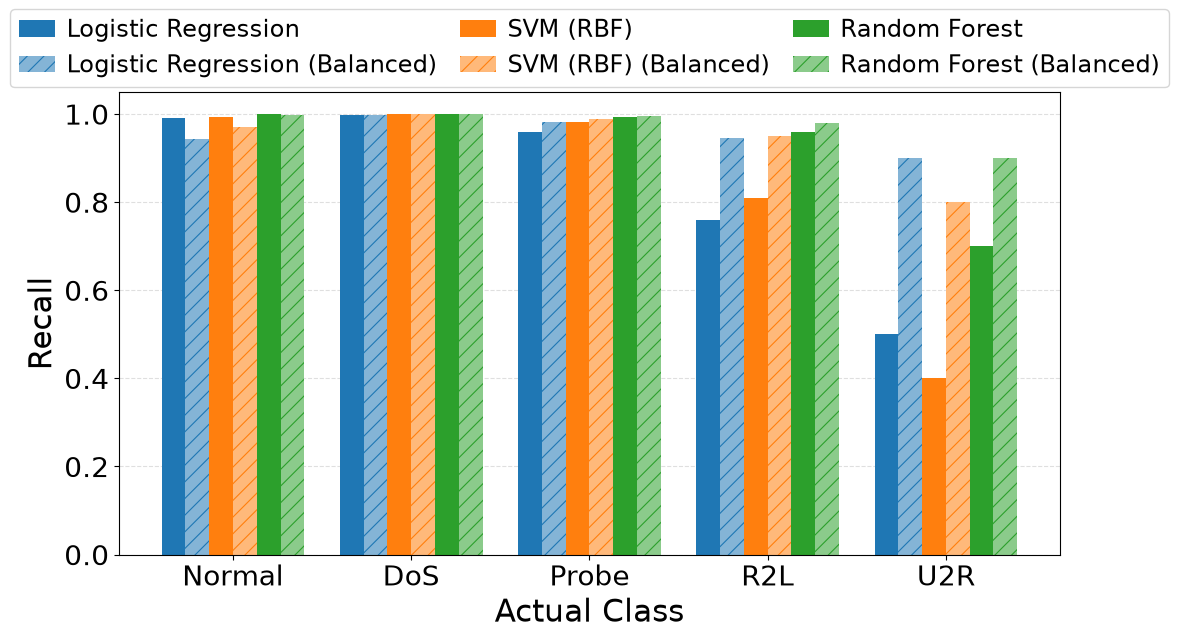

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
 
classes = ["Normal", "DoS", "Probe", "R2L", "U2R"]
 
recall = {
    # validation recall; each model is followed by its class-weighted version
    "Logistic Regression":            [0.992, 0.998, 0.960, 0.759, 0.500],
    "Logistic Regression (Balanced)": [0.943, 0.999, 0.983, 0.945, 0.900],
    "SVM (RBF)":                      [0.994, 1.000, 0.982, 0.809, 0.400],
    "SVM (RBF) (Balanced)":           [0.971, 1.000, 0.988, 0.950, 0.800],
    "Random Forest":                  [1.000, 1.000, 0.993, 0.960, 0.700],
    "Random Forest (Balanced)":       [0.999, 1.000, 0.996, 0.980, 0.900],
}
 
# matplotlib default colours, as in the baseline figure
colors = {
    "Logistic Regression": "#1f77b4",
    "SVM (RBF)": "#ff7f0e",
    "Random Forest": "#2ca02c",
}
 
 
def lighten(color, amount=0.45):
    """Mix a colour with white."""
    r, g, b = to_rgb(color)
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)
 
 
plt.rcParams["font.family"] = "DejaVu Sans"   # matplotlib default, as in the baseline figure
plt.rcParams["hatch.linewidth"] = 0.8
plt.rcParams.update({
    "axes.labelsize": 22,         # "Actual Class", "Recall"
    "xtick.labelsize": 20,        # Normal, DoS, ...
    "ytick.labelsize": 20,        # 0.0, 0.2, ...
    "legend.fontsize": 17,        # legend entries
})
 
fig, ax = plt.subplots(figsize=(12, 6.5))
 
n_series = len(recall)
width = 0.8 / n_series
x = np.arange(len(classes))
 
for i, (name, values) in enumerate(recall.items()):
    balanced = "(Balanced)" in name
    base_color = colors[name.replace(" (Balanced)", "")]
    offset = (i - (n_series - 1) / 2) * width
    if balanced:
        ax.bar(x + offset, values, width, label=name,
               color=lighten(base_color), hatch="//",
               edgecolor=base_color, linewidth=0)
    else:
        ax.bar(x + offset, values, width, label=name, color=base_color)
 
ax.set_xlabel("Actual Class")
ax.set_ylabel("Recall")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0, 1.05)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
 
# Boxed legend directly above the plot, laid out horizontally
# (outside the axes so the larger font has the full figure width).
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3,
          frameon=True, handlelength=1.5, columnspacing=1.0,
          handletextpad=0.5, borderaxespad=0)
 
fig.tight_layout()
fig.savefig("fig_validation_recall.pdf", bbox_inches="tight")
fig.savefig("fig_validation_recall.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:
# Step 9 : Freeze the model selection

In [23]:
#Freeze the selected configuration
selected_model_name = 'Random Forest (Balanced)'

selected_validation_row = validation_results_df[
    validation_results_df['Model'] == selected_model_name
]

print("Frozen model:", selected_model_name)
display(selected_validation_row)


Frozen model: Random Forest (Balanced)


,Model,Accuracy,Macro-F1,Weighted-F1
5,Random Forest (Balanced),0.999,0.968,0.999


In [24]:
# Step 7: RF-Balanced official test evaluation

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time
import pandas as pd

class_order = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']

# Clone the selected pipeline, retaining its configuration
final_model = clone(all_models[selected_model_name])

# Fit on the complete official training dataset
start_time = time.time()
final_model.fit(X_full, y_full)
final_training_time = time.time() - start_time

print(f"Final training time: {final_training_time:.2f} seconds")

# Predict on the official test dataset
y_test_pred = final_model.predict(X_official_test)

print("\nOfficial KDDTest+ results")
print(f"Selected model: {selected_model_name}")
print(f"Accuracy: {accuracy_score(y_official_test, y_test_pred):.4f}")
print(
    f"Macro-F1: {f1_score(y_official_test, y_test_pred, labels=class_order, average='macro', zero_division=0):.4f}"
)
print(
    f"Weighted-F1: {f1_score(y_official_test, y_test_pred, labels=class_order, average='weighted', zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_official_test,
    y_test_pred,
    labels=class_order,
    digits=4,
    zero_division=0
))

print("\nConfusion matrix:")
display(pd.DataFrame(
    confusion_matrix(
        y_official_test,
        y_test_pred,
        labels=class_order
    ),
    index=class_order,
    columns=class_order
))


Final training time: 11.37 seconds

Official KDDTest+ results
Selected model: Random Forest (Balanced)
Accuracy: 0.7470
Macro-F1: 0.5168
Weighted-F1: 0.7012

Classification report:
              precision    recall  f1-score   support

      Normal     0.6459    0.9724    0.7762      9711
         DoS     0.9608    0.7654    0.8520      7460
       Probe     0.8533    0.6799    0.7568      2421
         R2L     0.8750    0.0121    0.0239      2885
         U2R     0.5385    0.1045    0.1750        67

    accuracy                         0.7470     22544
   macro avg     0.7747    0.5069    0.5168     22544
weighted avg     0.8014    0.7470    0.7012     22544


Confusion matrix:


,Normal,DoS,Probe,R2L,U2R
Normal,9443,67,198,1,2
DoS,1679,5710,71,0,0
Probe,609,166,1646,0,0
R2L,2832,0,14,35,4
U2R,56,0,0,4,7


In [25]:
# However, we would like to test the performance of all three models on offcial test set to check if the validation 
# phase winner RF-Balanced will provide the same performance

In [26]:
#Step 8: Train the models and measure training time

import time


training_results = []

for name, model in models.items():
    print(f"Training {name}...")

    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    training_results.append({
        'Model': name,
        'Training Time (seconds)': round(training_time, 2)
    })

    print(f"{name} trained in {training_time:.2f} seconds\n")

training_time_df = pd.DataFrame(training_results)
display(training_time_df)

#What are we measuring?
#- Training time: time required to fit the complete pipeline, including preprocessing and model training.
#- All three models use the same official training records, so their results are comparable.
#- The fitted models are stored in the models dictionary for evaluation in the next step.
#Note: RBF SVM may take considerably longer than Logistic Regression or Random Forest. 
#Let the cell finish; don't interrupt it unless it appears stuck for an unusually long time.

Training Logistic Regression...
Logistic Regression trained in 29.66 seconds

Training SVM (RBF)...
SVM (RBF) trained in 71.12 seconds

Training Random Forest...
Random Forest trained in 12.58 seconds



,Model,Training Time (seconds)
0,Logistic Regression,29.660
1,SVM (RBF),71.120
2,Random Forest,12.580


In [27]:
#Step 9: Evaluate the models on the official test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

evaluation_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    y_pred = model.predict(X_test)

    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro Precision': precision_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Macro Recall': recall_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Macro F1': f1_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Weighted F1': f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    })

    print(f"\nClassification report: {name}")
    print(classification_report(y_test, y_pred, zero_division=0))

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.style.format({
        'Accuracy': '{:.4f}',
        'Macro Precision': '{:.4f}',
        'Macro Recall': '{:.4f}',
        'Macro F1': '{:.4f}',
        'Weighted F1': '{:.4f}'
    })
)

#Why look beyond accuracy?
#The test set contains 9,711 Normal samples but only 67 U2R samples. A model can achieve high overall accuracy while performing poorly on a rare attack class.
#- Macro-F1: treats all five classes equally.
#- Weighted F1: gives more weight to classes with more samples.
#- Per-class recall: shows how many attacks of each category the model successfully detects.

Evaluating Logistic Regression...

Classification report: Logistic Regression
              precision    recall  f1-score   support

         DoS       0.92      0.83      0.87      7460
      Normal       0.67      0.93      0.78      9711
       Probe       0.88      0.78      0.82      2421
         R2L       0.65      0.02      0.03      2885
         U2R       0.77      0.25      0.38        67

    accuracy                           0.76     22544
   macro avg       0.78      0.56      0.58     22544
weighted avg       0.77      0.76      0.72     22544

Evaluating SVM (RBF)...

Classification report: SVM (RBF)
              precision    recall  f1-score   support

         DoS       0.96      0.77      0.86      7460
      Normal       0.65      0.97      0.78      9711
       Probe       0.84      0.61      0.71      2421
         R2L       0.98      0.08      0.14      2885
         U2R       0.67      0.03      0.06        67

    accuracy                           0.75     2

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Logistic Regression,0.7614,0.7778,0.5613,0.5774,0.7165
1,SVM (RBF),0.7493,0.8204,0.4913,0.5075,0.7121
2,Random Forest,0.7451,0.7870,0.4846,0.4975,0.7046


In [28]:
#What do these results tell us?
#- Logistic Regression performs best overall among these three models on accuracy, macro recall, macro-F1, and weighted F1.
#- SVM has the highest macro precision (0.8368), but its lower macro recall means it misses more actual samples across classes on average.
#- Random Forest does not perform best here, despite being the fastest to train.
#The macro-F1 scores are substantially lower than the accuracy scores. This suggests performance varies across the five classes, 
#so we should not conclude that the models detect every attack category equally well.

In [29]:
#helper function for deeper analysis
def unique_values(df, columns):
    """Prints unique values and their counts for specific columns in the DataFrame."""

    for column_name in columns:
        print(f"Column: {column_name}\n{'-'*30}")
        unique_vals = df[column_name].unique()
        value_counts = df[column_name].value_counts()
        print(f"Unique Values ({len(unique_vals)}): {unique_vals}\n")
        print(f"Value Counts:\n{value_counts}\n{'='*40}\n")

In [30]:
#Step 10: Compare per-class performance

from sklearn.metrics import classification_report

class_f1_results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    report = classification_report(
        y_test,
        y_pred,
        labels=['Normal', 'DoS', 'Probe', 'R2L', 'U2R'],
        output_dict=True,
        zero_division=0
    )

    for category in ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']:
        class_f1_results.append({
            'Model': name,
            'Class': category,
            'Precision': report[category]['precision'],
            'Recall': report[category]['recall'],
            'F1-score': report[category]['f1-score'],
            'Support': report[category]['support']
        })

class_results_df = pd.DataFrame(class_f1_results)

display(
    class_results_df.pivot(
        index='Class',
        columns='Model',
        values='F1-score'
    ).round(4)
)

Model,Logistic Regression,Random Forest,SVM (RBF)
Class,,,
DoS,0.871,0.855,0.855
Normal,0.776,0.774,0.778
Probe,0.825,0.705,0.706
R2L,0.033,0.098,0.141
U2R,0.382,0.056,0.057


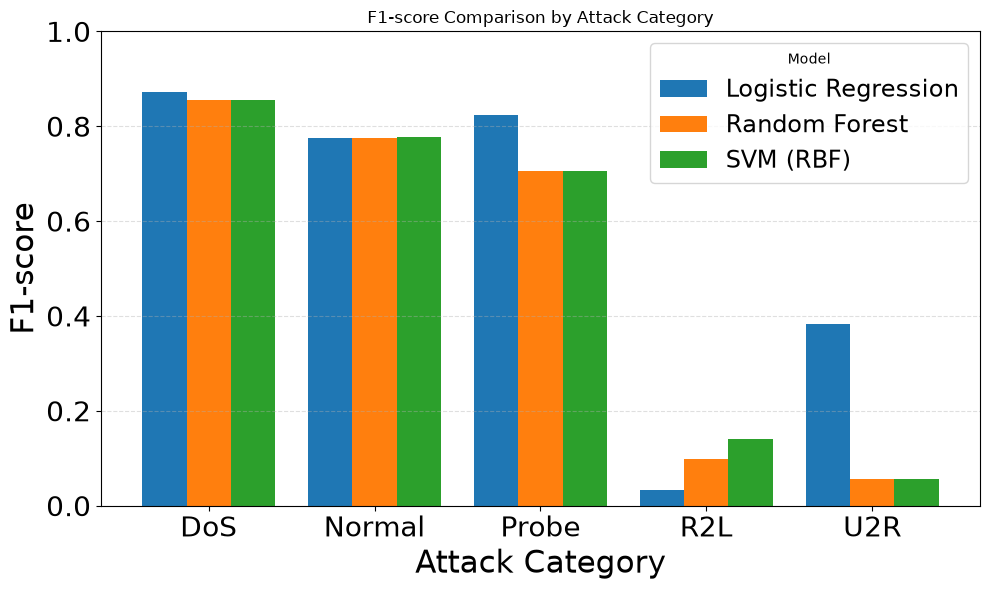

In [31]:
import matplotlib.pyplot as plt

# Plot F1-score comparison using the existing DataFrame
f1_pivot = class_results_df.pivot(
    index='Class',
    columns='Model',
    values='F1-score'
)

ax = f1_pivot.plot(kind='bar', figsize=(10, 6), width=0.8)

ax.set_title('F1-score Comparison by Attack Category')
ax.set_xlabel('Attack Category')
ax.set_ylabel('F1-score')
ax.set_ylim(0, 1.0)
ax.legend(title='Model')
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    'validation_multiclass_F1_score.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

#Key findings
#- Logistic Regression is the strongest baseline overall. It has the highest overall accuracy (76.05%) and macro-F1 (0.5753).
#- R2L is the biggest challenge. Even the best F1-score is only 0.153, suggesting the models struggle to distinguish these attacks 
#from other traffic.
#- U2R results are unstable. Logistic Regression achieves the highest U2R F1-score (0.382), but the training set 
#contains only 52 U2R records.
#- Accuracy alone is insufficient. The class-level results show why macro-F1 and per-class recall matter for intrusion detection.

In [32]:
#2. Why might R2L and U2R be difficult?
#Your training distribution is highly imbalanced:
#- Normal: 67,343 records
#- DoS: 45,927 records
#- Probe: 11,656 records
#- R2L: 995 records
#- U2R: 52 records
##The models have very few examples from which to learn the characteristics of R2L and U2R. 
#Additionally, the official test set includes attack types not seen by name during training.
#Although these attacks map to known categories, recognizing their patterns is a harder generalization problem.

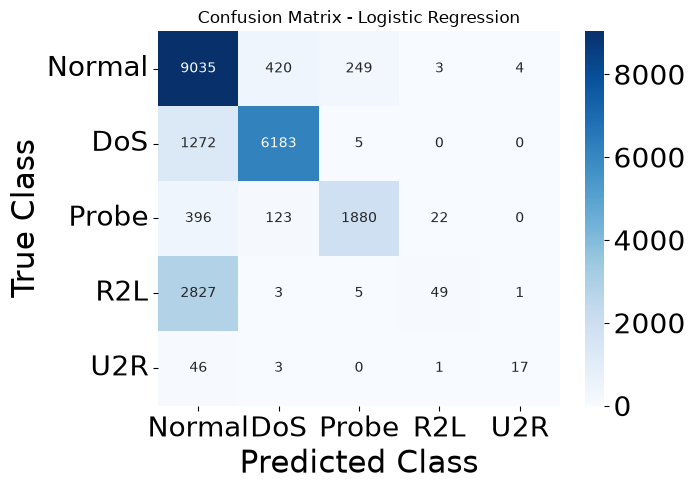

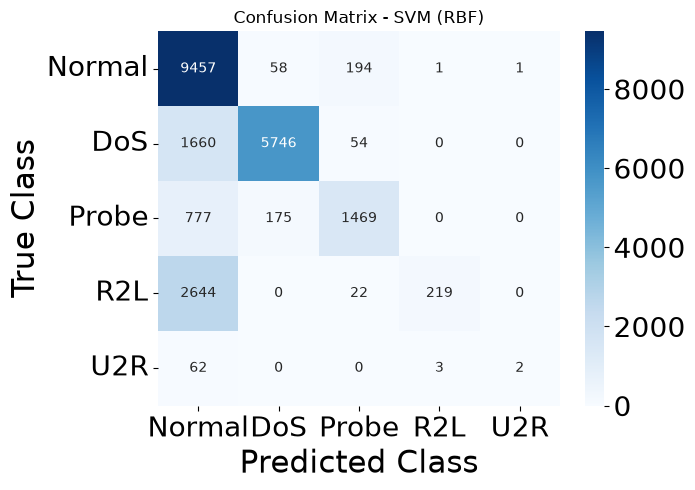

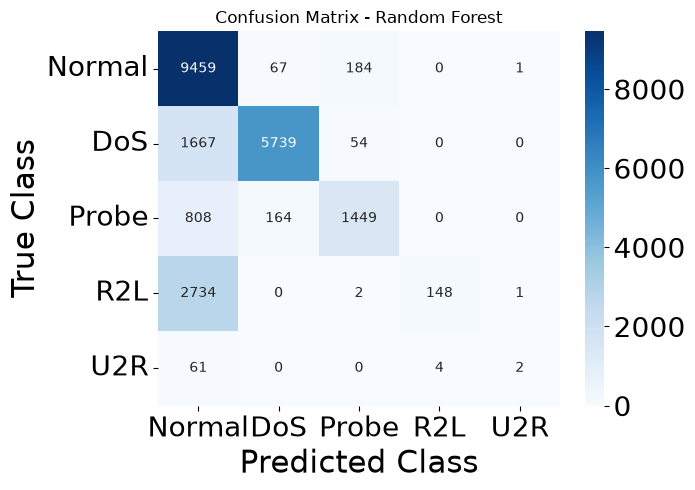

In [33]:
#3. Next step: inspect the confusion matrices
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_order = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']

for name, model in models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_order
    )

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_order,
        yticklabels=class_order
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Class')
    plt.ylabel('True Class')
    plt.tight_layout()

    plt.savefig(
    f'validation_multiclass_confusion_matrix_{name.replace(" ", "_").replace("(", "").replace(")", "")}.png',
    dpi=300,
    bbox_inches='tight')

    plt.show()

In [34]:
#Calculate per-class recall directly from your matrices
from sklearn.metrics import confusion_matrix
import pandas as pd

class_order = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']
recall_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test, y_pred, labels=class_order
    )

    # Diagonal / total samples in each actual class
    recalls = cm.diagonal() / cm.sum(axis=1)

    recall_results[name] = recalls

recall_df = pd.DataFrame(
    recall_results,
    index=class_order
)

recall_df.index.name = 'Actual Class'

display(recall_df.round(4))

,Logistic Regression,SVM (RBF),Random Forest
Actual Class,,,
Normal,0.930,0.974,0.974
DoS,0.829,0.770,0.769
Probe,0.776,0.607,0.599
R2L,0.017,0.076,0.051
U2R,0.254,0.030,0.030


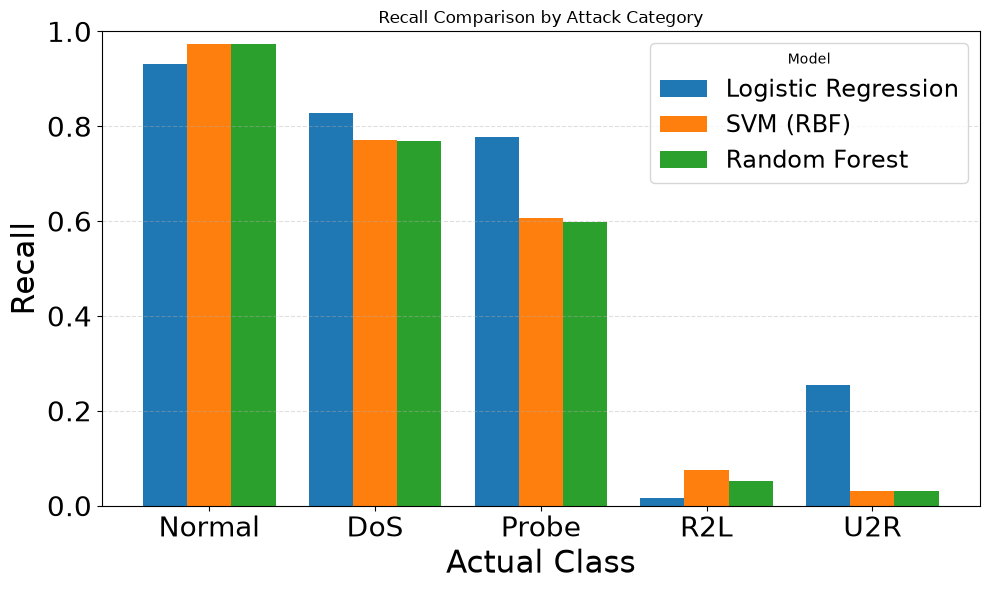

In [35]:
import matplotlib.pyplot as plt

# Plot recall comparison by class
ax = recall_df.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8
)

ax.set_title('Recall Comparison by Attack Category')
ax.set_xlabel('Actual Class')
ax.set_ylabel('Recall')
ax.set_ylim(0, 1.0)
ax.legend(title='Model')
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.xticks(rotation=0)
plt.tight_layout()

# Save figure before displaying it
plt.savefig(
    'validation_multiclass_recall_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [36]:
#Key findings
#- Normal traffic: SVM and Random Forest correctly identify 97.3% of actual Normal samples.
#- DoS attacks: Logistic Regression performs best, detecting 83.0% of actual DoS samples.
#- Probe attacks: Logistic Regression also leads, with 77.2% recall.
#- R2L attacks: Recall is very poor for all models. Even SVM detects only 8.3% of actual R2L samples.
#- U2R attacks: Logistic Regression performs best, but detects only 25.4% of actual U2R samples.
#2. Why these results matter
#Recall is particularly important in intrusion detection because a low recall means many actual attacks go undetected.
#For example, SVM's R2L recall of 0.083 means it detects only about 8 out of every 100 actual R2L samples, while missing roughly 92.

In [37]:
#Step 11: Define class-weighted models

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Class-weighted Logistic Regression
lr_balanced = Pipeline([
    ('preprocessing', scaled_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    ))
])

# Class-weighted SVM (RBF)
svm_balanced = Pipeline([
    ('preprocessing', scaled_preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        random_state=42,
        class_weight='balanced'
    ))
])

# Class-weighted Random Forest
rf_balanced = Pipeline([
    ('preprocessing', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

balanced_models = {
    'Logistic Regression (Balanced)': lr_balanced,
    'SVM (RBF, Balanced)': svm_balanced,
    'Random Forest (Balanced)': rf_balanced
}

print("Class-weighted models defined:")
for name in balanced_models:
    print("-", name)

Class-weighted models defined:
- Logistic Regression (Balanced)
- SVM (RBF, Balanced)
- Random Forest (Balanced)


In [38]:
#Step 12: Train the class-weighted models
import time
import pandas as pd

balanced_training_results = []

for name, model in balanced_models.items():
    print(f"Training {name}...")

    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    balanced_training_results.append({
        'Model': name,
        'Training Time (seconds)': round(training_time, 2)
    })

    print(f"{name} trained in {training_time:.2f} seconds\n")

balanced_training_time_df = pd.DataFrame(balanced_training_results)
display(balanced_training_time_df)

Training Logistic Regression (Balanced)...
Logistic Regression (Balanced) trained in 103.88 seconds

Training SVM (RBF, Balanced)...
SVM (RBF, Balanced) trained in 579.44 seconds

Training Random Forest (Balanced)...
Random Forest (Balanced) trained in 9.49 seconds



,Model,Training Time (seconds)
0,Logistic Regression (Balanced),103.880
1,"SVM (RBF, Balanced)",579.440
2,Random Forest (Balanced),9.490


In [39]:
#Step 13: Evaluate the balanced models

In [40]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report
)
import pandas as pd

balanced_evaluation_results = []
balanced_recall_results = []

class_order = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']

for name, model in balanced_models.items():
    print(f"Evaluating {name}...")

    y_pred = model.predict(X_test)

    balanced_evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Weighted F1': f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    })

    report = classification_report(
        y_test,
        y_pred,
        labels=class_order,
        output_dict=True,
        zero_division=0
    )

    for category in class_order:
        balanced_recall_results.append({
            'Model': name,
            'Class': category,
            'Recall': report[category]['recall']
        })

    print("\n", classification_report(
        y_test, y_pred, labels=class_order, zero_division=0
    ))

balanced_evaluation_df = pd.DataFrame(balanced_evaluation_results)
balanced_recall_df = pd.DataFrame(balanced_recall_results)

print("Overall performance:")
display(balanced_evaluation_df.round(4))

print("Per-class recall:")
display(
    balanced_recall_df.pivot(
        index='Class', columns='Model', values='Recall'
    ).round(4)
)

Evaluating Logistic Regression (Balanced)...

               precision    recall  f1-score   support

      Normal       0.74      0.91      0.82      9711
         DoS       0.92      0.83      0.87      7460
       Probe       0.83      0.86      0.84      2421
         R2L       0.89      0.23      0.37      2885
         U2R       0.07      0.48      0.12        67

    accuracy                           0.79     22544
   macro avg       0.69      0.66      0.60     22544
weighted avg       0.82      0.79      0.78     22544

Evaluating SVM (RBF, Balanced)...

               precision    recall  f1-score   support

      Normal       0.68      0.97      0.80      9711
         DoS       0.96      0.77      0.85      7460
       Probe       0.82      0.71      0.76      2421
         R2L       0.96      0.12      0.22      2885
         U2R       0.05      0.24      0.09        67

    accuracy                           0.76     22544
   macro avg       0.70      0.56      0.54     

,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression (Balanced),0.792,0.604,0.778
1,"SVM (RBF, Balanced)",0.763,0.543,0.736
2,Random Forest (Balanced),0.749,0.521,0.708


Per-class recall:


Model,Logistic Regression (Balanced),Random Forest (Balanced),"SVM (RBF, Balanced)"
Class,,,
DoS,0.831,0.773,0.769
Normal,0.914,0.972,0.968
Probe,0.858,0.636,0.706
R2L,0.232,0.045,0.122
U2R,0.478,0.090,0.239


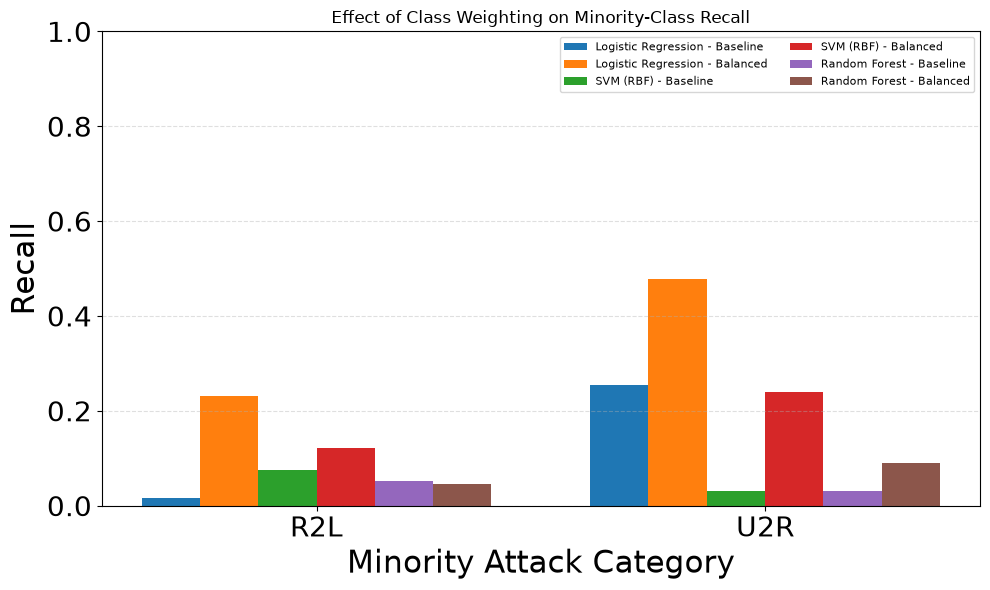

In [41]:
import matplotlib.pyplot as plt
import numpy as np

minority_classes = ['R2L', 'U2R']
baseline_names = [
    'Logistic Regression', 'SVM (RBF)', 'Random Forest'
]
balanced_names = [
    'Logistic Regression (Balanced)',
    'SVM (RBF, Balanced)',
    'Random Forest (Balanced)'
]

x = np.arange(len(minority_classes))
width = 0.13

fig, ax = plt.subplots(figsize=(10, 6))

for i, (base, balanced) in enumerate(
    zip(baseline_names, balanced_names)
):
    base_values = recall_df.loc[minority_classes, base].values
    balanced_values = balanced_recall_df[
        balanced_recall_df['Model'] == balanced
    ].set_index('Class').loc[minority_classes, 'Recall'].values

    offset = (i - 1) * 2 * width

    ax.bar(
        x + offset - width / 2,
        base_values,
        width,
        label=f'{base} - Baseline'
    )
    ax.bar(
        x + offset + width / 2,
        balanced_values,
        width,
        label=f'{base} - Balanced'
    )

ax.set_xlabel('Minority Attack Category')
ax.set_ylabel('Recall')
ax.set_title('Effect of Class Weighting on Minority-Class Recall')
ax.set_xticks(x)
ax.set_xticklabels(minority_classes)
ax.set_ylim(0, 1)
ax.legend(fontsize=8, ncol=2)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig(
    'validation_class_weighting_minority_recall.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [42]:
import pandas as pd

# Extract baseline overall metrics
baseline_overall = evaluation_df.set_index('Model')[
    ['Accuracy', 'Macro F1', 'Weighted F1']
].copy()

# Extract balanced overall metrics
balanced_overall = balanced_evaluation_df.set_index('Model')[
    ['Accuracy', 'Macro F1', 'Weighted F1']
].copy()

# Match each baseline model to its balanced version
model_pairs = {
    'Logistic Regression': 'Logistic Regression (Balanced)',
    'SVM (RBF)': 'SVM (RBF, Balanced)',
    'Random Forest': 'Random Forest (Balanced)'
}

comparison_rows = []

for baseline_name, balanced_name in model_pairs.items():
    baseline = baseline_overall.loc[baseline_name]
    balanced = balanced_overall.loc[balanced_name]

    for metric in ['Accuracy', 'Macro F1', 'Weighted F1']:
        comparison_rows.append({
            'Model': baseline_name,
            'Metric': metric,
            'Baseline': baseline[metric],
            'Balanced': balanced[metric],
            'Change': balanced[metric] - baseline[metric]
        })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        'Baseline': '{:.4f}',
        'Balanced': '{:.4f}',
        'Change': '{:+.4f}'
    })
)

,Model,Metric,Baseline,Balanced,Change
0,Logistic Regression,Accuracy,0.7614,0.7920,+0.0307
1,Logistic Regression,Macro F1,0.5774,0.6039,+0.0265
2,Logistic Regression,Weighted F1,0.7165,0.7777,+0.0612
3,SVM (RBF),Accuracy,0.7493,0.7633,+0.0140
4,SVM (RBF),Macro F1,0.5075,0.5434,+0.0359
5,SVM (RBF),Weighted F1,0.7121,0.7360,+0.0239
6,Random Forest,Accuracy,0.7451,0.7490,+0.0039
7,Random Forest,Macro F1,0.4975,0.5209,+0.0234
8,Random Forest,Weighted F1,0.7046,0.7081,+0.0035


In [43]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import pandas as pd

metrics = [
    'Accuracy', 'Macro Precision', 'Macro Recall',
    'Macro F1', 'Weighted F1'
]

def calculate_metrics(model_dict):
    results = []

    for name, model in model_dict.items():
        y_pred = model.predict(X_test)

        results.append({
            'Model': name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Macro Precision': precision_score(
                y_test, y_pred, average='macro', zero_division=0
            ),
            'Macro Recall': recall_score(
                y_test, y_pred, average='macro', zero_division=0
            ),
            'Macro F1': f1_score(
                y_test, y_pred, average='macro', zero_division=0
            ),
            'Weighted F1': f1_score(
                y_test, y_pred, average='weighted', zero_division=0
            )
        })

    return pd.DataFrame(results)

# Recalculate metrics for both sets of models
evaluation_df = calculate_metrics(models)
balanced_evaluation_df = calculate_metrics(balanced_models)

# Compare baseline and balanced models
model_pairs = {
    'Logistic Regression': 'Logistic Regression (Balanced)',
    'SVM (RBF)': 'SVM (RBF, Balanced)',
    'Random Forest': 'Random Forest (Balanced)'
}

comparison_rows = []

baseline_indexed = evaluation_df.set_index('Model')
balanced_indexed = balanced_evaluation_df.set_index('Model')

for baseline_name, balanced_name in model_pairs.items():
    for metric in metrics:
        baseline_value = baseline_indexed.loc[baseline_name, metric]
        balanced_value = balanced_indexed.loc[balanced_name, metric]

        comparison_rows.append({
            'Model': baseline_name,
            'Metric': metric,
            'Baseline': baseline_value,
            'Balanced': balanced_value,
            'Change': balanced_value - baseline_value
        })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        'Baseline': '{:.4f}',
        'Balanced': '{:.4f}',
        'Change': '{:+.4f}'
    })
)

,Model,Metric,Baseline,Balanced,Change
0,Logistic Regression,Accuracy,0.7614,0.7920,+0.0307
1,Logistic Regression,Macro Precision,0.7778,0.6881,-0.0897
2,Logistic Regression,Macro Recall,0.5613,0.6625,+0.1012
3,Logistic Regression,Macro F1,0.5774,0.6039,+0.0265
4,Logistic Regression,Weighted F1,0.7165,0.7777,+0.0612
5,SVM (RBF),Accuracy,0.7493,0.7633,+0.0140
6,SVM (RBF),Macro Precision,0.8204,0.6954,-0.1251
7,SVM (RBF),Macro Recall,0.4913,0.5607,+0.0693
8,SVM (RBF),Macro F1,0.5075,0.5434,+0.0359
9,SVM (RBF),Weighted F1,0.7121,0.7360,+0.0239


In [44]:
#False-positive rate for detecting any attack versus Normal traffic
from sklearn.metrics import confusion_matrix
import pandas as pd

binary_fpr_results = []

for group_name, model_dict in [
    ('Baseline', models),
    ('Balanced', balanced_models)
]:
    for name, model in model_dict.items():
        y_pred = model.predict(X_test)

        # Convert five-class labels to binary: Normal vs Attack
        y_true_binary = (y_test != 'Normal').astype(int)
        y_pred_binary = (y_pred != 'Normal').astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true_binary, y_pred_binary, labels=[0, 1]
        ).ravel()

        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        binary_fpr_results.append({
            'Experiment': group_name,
            'Model': name,
            'False Positives': fp,
            'True Negatives': tn,
            'Binary False-Positive Rate': fpr
        })

binary_fpr_df = pd.DataFrame(binary_fpr_results)

display(
    binary_fpr_df.style.format({
        'Binary False-Positive Rate': '{:.4f}'
    })
)

,Experiment,Model,False Positives,True Negatives,Binary False-Positive Rate
0,Baseline,Logistic Regression,676,9035,0.0696
1,Baseline,SVM (RBF),254,9457,0.0262
2,Baseline,Random Forest,252,9459,0.0259
3,Balanced,Logistic Regression (Balanced),831,8880,0.0856
4,Balanced,"SVM (RBF, Balanced)",315,9396,0.0324
5,Balanced,Random Forest (Balanced),273,9438,0.0281


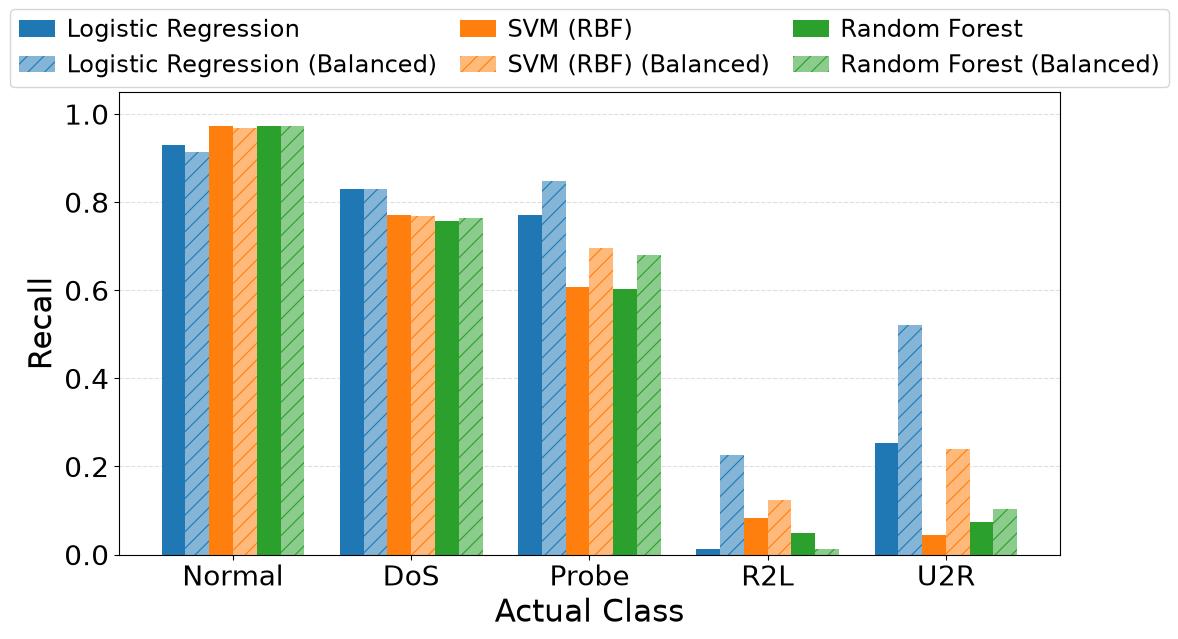

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
 
classes = ["Normal", "DoS", "Probe", "R2L", "U2R"]
 
recall = {
    # test-set recall; each model is followed by its class-weighted version
    "Logistic Regression":            [0.930, 0.830, 0.772, 0.013, 0.254],
    "Logistic Regression (Balanced)": [0.914, 0.831, 0.847, 0.225, 0.522],
    "SVM (RBF)":                      [0.973, 0.771, 0.608, 0.083, 0.045],
    "SVM (RBF) (Balanced)":           [0.968, 0.768, 0.697, 0.123, 0.239],
    "Random Forest":                  [0.973, 0.757, 0.604, 0.049, 0.075],
    "Random Forest (Balanced)":       [0.972, 0.765, 0.680, 0.012, 0.104],
}
 
# matplotlib default colours, as in the baseline figure
colors = {
    "Logistic Regression": "#1f77b4",
    "SVM (RBF)": "#ff7f0e",
    "Random Forest": "#2ca02c",
}
 
 
def lighten(color, amount=0.45):
    """Mix a colour with white."""
    r, g, b = to_rgb(color)
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)
 
 
plt.rcParams["font.family"] = "DejaVu Sans"   # matplotlib default, as in the baseline figure
plt.rcParams["hatch.linewidth"] = 0.8
plt.rcParams.update({
    "axes.labelsize": 22,         # "Actual Class", "Recall"
    "xtick.labelsize": 20,        # Normal, DoS, ...
    "ytick.labelsize": 20,        # 0.0, 0.2, ...
    "legend.fontsize": 17,        # legend entries
})
 
fig, ax = plt.subplots(figsize=(12, 6.5))
 
n_series = len(recall)
width = 0.8 / n_series
x = np.arange(len(classes))
 
for i, (name, values) in enumerate(recall.items()):
    balanced = "(Balanced)" in name
    base_color = colors[name.replace(" (Balanced)", "")]
    offset = (i - (n_series - 1) / 2) * width
    if balanced:
        ax.bar(x + offset, values, width, label=name,
               color=lighten(base_color), hatch="//",
               edgecolor=base_color, linewidth=0)
    else:
        ax.bar(x + offset, values, width, label=name, color=base_color)
 
ax.set_xlabel("Actual Class")
ax.set_ylabel("Recall")
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylim(0, 1.05)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
 
# Boxed legend directly above the plot, laid out horizontally
# (outside the axes so the larger font has the full figure width).
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3,
          frameon=True, handlelength=1.5, columnspacing=1.0,
          handletextpad=0.5, borderaxespad=0)
 
fig.tight_layout()
fig.savefig("fig_test_recall.pdf", bbox_inches="tight")
fig.savefig("fig_test_recall.png", dpi=300, bbox_inches="tight")
plt.show()